# Monte Carlo Simulation to estimating π

## The idea

Take a square of side 1 and draw inside it a quarter of a circle of radius 1, centred at the corner $(0, 0)$.

- Area of the square: $1$
- Area of the quarter disk: $\frac{\pi \cdot 1^2}{4} = \frac{\pi}{4}$

Now throw $n$ points **uniformly at random** in the square. Each point is equally likely to land anywhere, so the fraction of points that fall inside the quarter disk is close to the ratio of the areas:

$$\frac{M}{n} \approx \frac{\pi / 4}{1} \quad\Longrightarrow\quad \pi \approx 4\,\frac{M}{n}$$

where $M$ is the number of points inside the quarter disk. The more points we throw, the better the approximation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def drawing(x, y, scatter = None):
    plt.plot(x, y, label='Quarter Circle', color='black', linewidth=0.5)
    plt.fill_between(x, y, color='#FF7F7F', alpha=0.5)
    if scatter is not None:
        plt.scatter(scatter[:, 0], scatter[:, 1], color='black', s=3, alpha=0.5, label='Random Samples')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)

## Is a point inside the quarter disk?

A point $(x, y)$ is inside the circle of radius 1 if its distance to the centre $(0, 0)$ is at most 1. By Pythagoras, this distance is $\sqrt{x^2 + y^2}$, so the test is simply:

$$x^2 + y^2 \le 1$$

(No square root needed: comparing the squares gives the same answer.)

In [3]:
rng = np.random.default_rng()

def monte_carlo(num_samples=10000):
    x = rng.random(num_samples, dtype=np.float32)                  # uniformly distributed random samples in [0, 1] x [0, 1]
    y = rng.random(num_samples, dtype=np.float32)
    M = np.count_nonzero(x*x + y*y <= 1)                           # M is in the circle (of center (0,0)) if x^2 + y^2 <= 1
    pi_estimate = (M / num_samples) * 4
    return np.column_stack((x, y)), pi_estimate

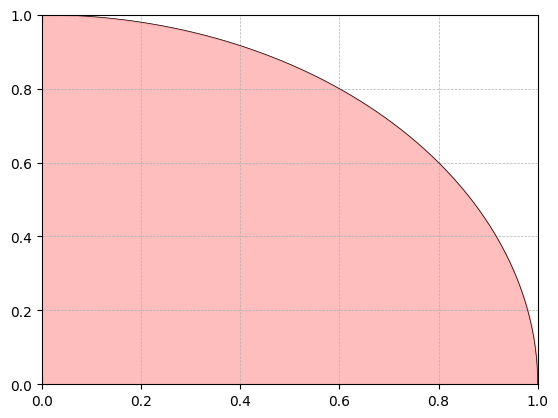

In [4]:
# Drawing quart circle of radius 1 in the first quadrant
x = np.linspace(0, 1, 1000)
y = np.sqrt(1 - x**2)

drawing(x, y)

## Let's try it

We throw 1000 points. The points that fall in the red area count as "inside". Run the cell several times: the estimate changes every time, because the points are random. It is close to $\pi$, but not exactly equal.

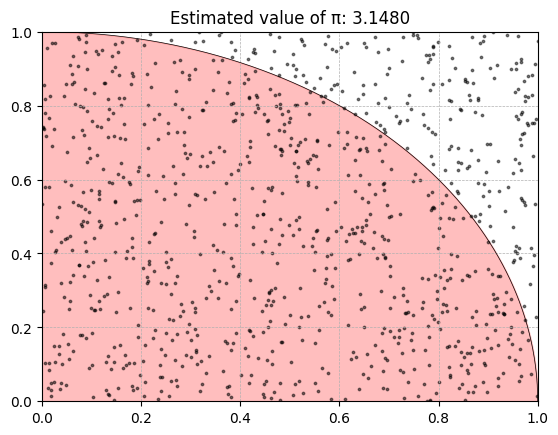

In [5]:
samples, pi_estimate = monte_carlo(num_samples=1000)
plt.title(f'Estimated value of π: {pi_estimate:.4f}')
drawing(x, y, scatter=samples)

# Benchmark Time

## How precise is the estimate?

Each point is like a coin flip: it lands inside with probability $p = \pi/4 \approx 0.785$, outside otherwise. For such a "yes / no" experiment, probability theory gives the spread of the fraction $M/n$:

$$\text{std}\left(\frac{M}{n}\right) = \sqrt{\frac{p(1-p)}{n}}$$

Our estimate is $4 \cdot M/n$, so its typical error is

$$\text{std}(\hat\pi) = 4\sqrt{\frac{p(1-p)}{n}} = \sqrt{\frac{\pi(4-\pi)}{n}} \approx \frac{1.64}{\sqrt{n}}$$

**Key takeaway:** the error decreases like $1/\sqrt{n}$. To get **10 times** more precise, we need **100 times** more points.

To check this, we run 100 independent simulations of $10^7$ points each, and record the estimate along the way. Looking at how the 100 runs spread out tells us the real error.

In [6]:
import numba

@numba.njit(parallel=True, fastmath=True)
def monte_carlo_numba(n):
    m = 0
    for i in numba.prange(n):
        x = np.random.random()
        y = np.random.random()
        if x*x + y*y <= 1:
            m += 1
    return (m / n) * 4

@numba.njit(parallel=True)
def many_runs(n_runs, n, step=1000):
    # Each row is an independent run: running estimate of π every `step` samples
    k = n // step
    out = np.empty((n_runs, k))
    for r in numba.prange(n_runs):                                 # runs are independent -> one per thread
        m = 0
        for i in range(k):
            for _ in range(step):
                x, y = np.random.random(), np.random.random()
                if x*x + y*y <= 1:
                    m += 1
            out[r, i] = (m / ((i + 1) * step)) * 4
    return out

In [7]:
NUM_SAMPLES = 10_000_000
STEP        = 10
N_RUNS      = 100

runs = many_runs(N_RUNS, NUM_SAMPLES, STEP)                        # shape (N_RUNS, NUM_SAMPLES // STEP)

n_values = STEP * np.arange(1, runs.shape[1] + 1)
print(n_values.shape)

/home/ropouillard/.virtualenvs/MonteCarlo/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


(1000000,)


In [8]:
pi_mean  = runs.mean(axis=0)
pi_std   = runs.std(axis=0, ddof=1)                               

## Reading the plots

- **Left:** the estimate as a function of the number of points $n$. The grey curves are individual runs: they wobble a lot at first, then settle around $\pi$. The blue band (mean ± 1 std) shows how far a single run typically is from the truth; it gets narrower as $n$ grows.
- **Right:** the measured spread of the runs (std) compared with the formula $\sqrt{\pi(4-\pi)/n}$. On a log-log plot, $1/\sqrt{n}$ is a straight line of slope $-1/2$, and the two curves should overlap.

Averaging the 100 runs is the same as one big run of $100\,n$ points, so its error is $\sqrt{100} = 10$ times smaller than the error of one run.

n = 1e+07 : π = 3.141603 ± 5.5e-04 (std of one run)
Error on the mean of 100 runs : ± 5.5e-05


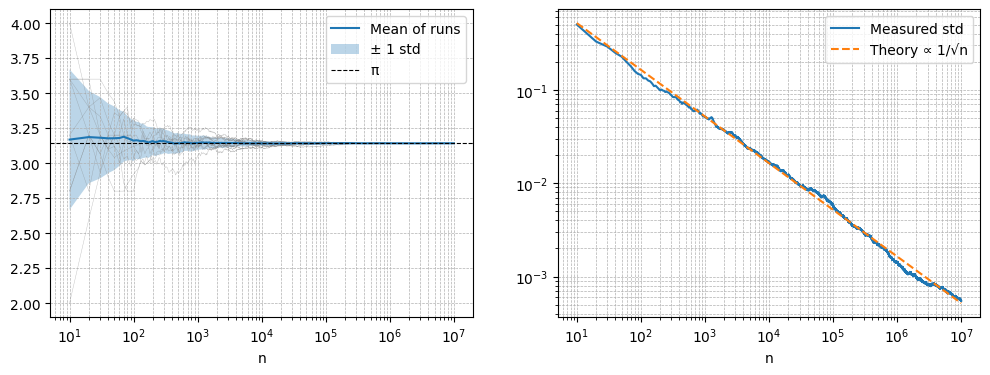

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Convergence: mean ± 1 std, with a few individual runs in the background
ax1.plot(n_values, runs[:10].T, color='gray', lw=0.3, alpha=0.5)
ax1.plot(n_values, pi_mean, color='C0', label='Mean of runs')
ax1.fill_between(n_values, pi_mean - pi_std, pi_mean + pi_std, alpha=0.3, label='± 1 std')
ax1.axhline(np.pi, color='black', ls='--', lw=0.8, label='π')
ax1.set_xscale('log'); ax1.set_xlabel('n'); ax1.legend()
ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

# Measured std vs theory: sqrt(π(4 - π) / n)
ax2.loglog(n_values, pi_std, label='Measured std')
ax2.loglog(n_values, np.sqrt(np.pi * (4 - np.pi) / n_values), '--', label='Theory ∝ 1/√n')
ax2.set_xlabel('n'); ax2.legend()
ax2.grid(True, which='both', linestyle='--', linewidth=0.5)


print(f'n = {n_values[-1]:.0e} : π = {pi_mean[-1]:.6f} ± {pi_std[-1]:.1e} (std of one run)')
print(f'Error on the mean of {N_RUNS} runs : ± {pi_std[-1] / np.sqrt(N_RUNS):.1e}')